In [ ]:
# libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('../data/cleaned/mobile_reviews_cleaned.csv', parse_dates=['review_date'])

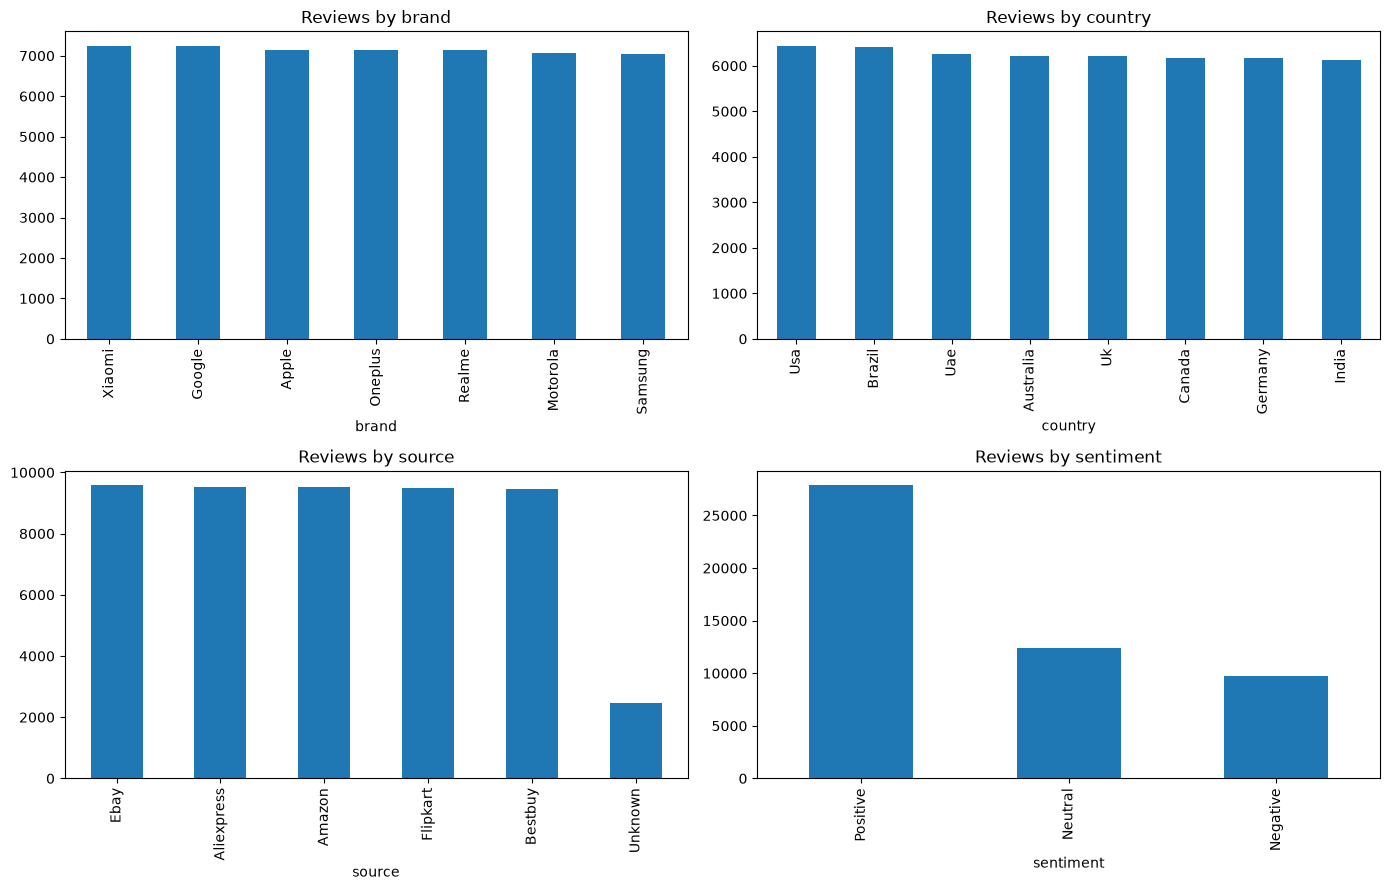

In [4]:
fig, ax = plt.subplots(2, 2, figsize=(14, 9))
for a, col in zip(ax.ravel(), ['brand', 'country', 'source', 'sentiment']):
    df[col].value_counts().plot(kind='bar', ax=a, title=f'Reviews by {col}')
plt.tight_layout(); plt.show()

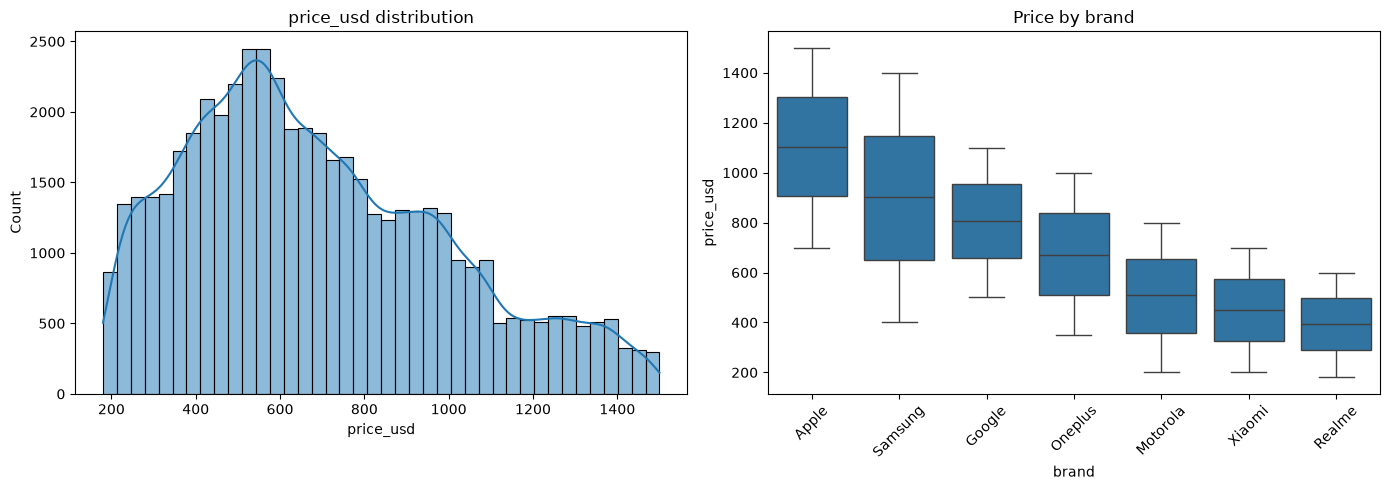

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data=df, x='price_usd', bins=40, kde=True, ax=ax[0])
ax[0].set_title('price_usd distribution')

order = df.groupby('brand')['price_usd'].median().sort_values(ascending=False).index
sns.boxplot(data=df, x='brand', y='price_usd', order=order, ax=ax[1])
ax[1].set_title('Price by brand')
ax[1].tick_params(axis='x', rotation=45)

plt.tight_layout(); plt.show()

In [10]:
# model-level summary
model_df = (df.groupby(['brand', 'model'])
              .agg(reviews=('rating', 'size'), avg_price=('price_usd', 'mean'), avg_rating=('rating', 'mean'))
              .round(2).sort_values('avg_price'))
print(model_df)

                          reviews  avg_price  avg_rating
brand    model                                          
Realme   Realme Narzo 70     3597     392.71        3.11
         Realme 12 Pro       3535     393.90        3.13
Xiaomi   Mi 13 Pro           2445     448.91        3.08
         Redmi Note 13       2470     449.78        3.11
         Poco X6             2326     450.27        3.10
Motorola Moto G Power        2351     504.61        3.12
         Razr 40             2395     506.15        3.10
         Edge 50             2315     508.70        3.07
Oneplus  Oneplus 12          2323     670.61        3.11
         Oneplus 11R         2433     672.79        3.10
         Oneplus Nord 3      2380     674.66        3.12
Google   Pixel 8             2387     798.97        3.10
         Pixel 7A            2468     806.82        3.11
         Pixel 6             2379     807.92        3.09
Samsung  Galaxy S24          1761     894.13        3.05
         Galaxy Z Flip       17

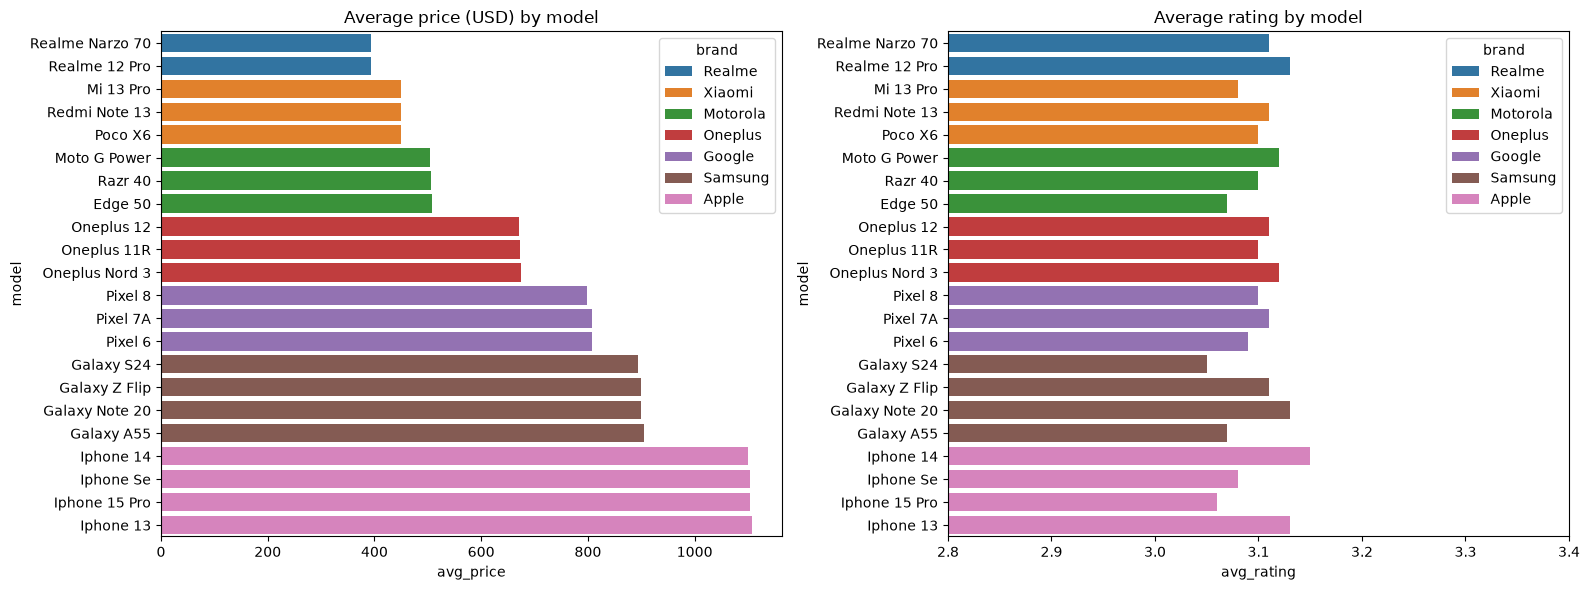

In [12]:
m = model_df.reset_index()

fig, ax = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(data=m, y='model', x='avg_price', hue='brand', dodge=False, ax=ax[0])
ax[0].set_title('Average price (USD) by model')

sns.barplot(data=m, y='model', x='avg_rating', hue='brand', dodge=False, ax=ax[1])
ax[1].set_xlim(2.8, 3.4)
ax[1].set_title('Average rating by model')

plt.tight_layout(); plt.show()

In [18]:
cols = ['avg_rating', 'reviews', 'avg_price']

print("TOP 5 models")
print(m.nlargest(5, 'avg_rating')[['brand', 'model'] + cols])
print("\nLOW 5 models")
print(m.nsmallest(5, 'avg_rating')[['brand', 'model'] + cols])

print("\n-------\n")

# brand-level and country-level
print(df.groupby('brand')['rating'].mean().round(3).sort_values(ascending=False))
print(df.groupby('country')['rating'].mean().round(3).sort_values(ascending=False))

TOP 5 models
       brand           model  avg_rating  reviews  avg_price
18     Apple       Iphone 14        3.15     1788    1099.22
1     Realme   Realme 12 Pro        3.13     3535     393.90
16   Samsung  Galaxy Note 20        3.13     1789     899.75
21     Apple       Iphone 13        3.13     1767    1108.27
5   Motorola    Moto G Power        3.12     2351     504.61

LOW 5 models
       brand          model  avg_rating  reviews  avg_price
14   Samsung     Galaxy S24        3.05     1761     894.13
20     Apple  Iphone 15 Pro        3.06     1793    1103.41
7   Motorola        Edge 50        3.07     2315     508.70
17   Samsung     Galaxy A55        3.07     1788     904.54
2     Xiaomi      Mi 13 Pro        3.08     2445     448.91

-------

brand
Realme      3.119
Oneplus     3.109
Apple       3.107
Google      3.100
Motorola    3.094
Samsung     3.094
Xiaomi      3.094
Name: rating, dtype: float64
country
Uae          3.123
Australia    3.113
Uk           3.103
Canada     

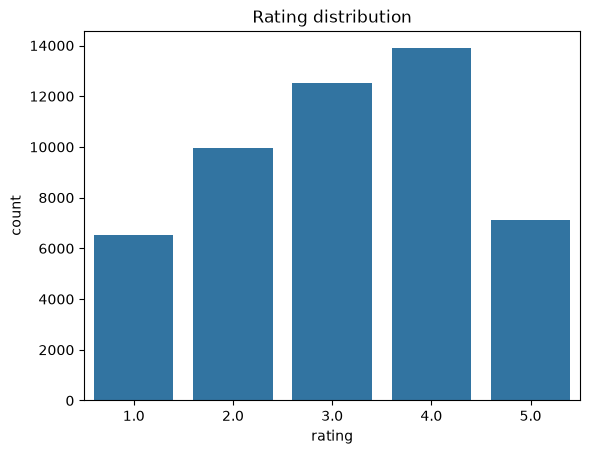

In [19]:
# rating distribution
sns.countplot(data=df, x='rating'); plt.title('Rating distribution'); plt.show()

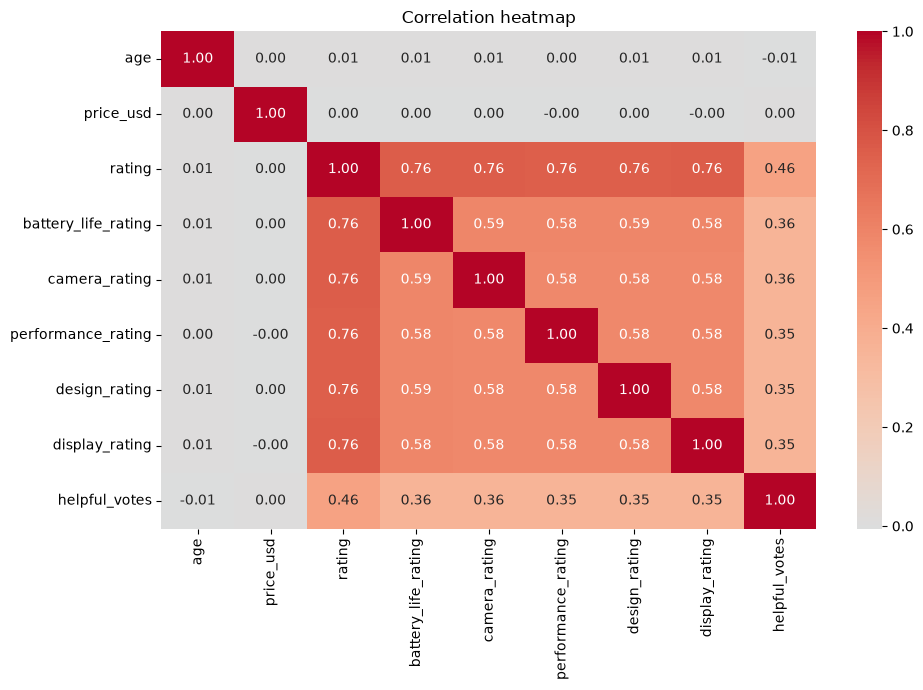

In [21]:
# correlation heatmap
corr_cols = ['age', 'price_usd', 'rating', 'battery_life_rating', 'camera_rating',
             'performance_rating', 'design_rating', 'display_rating', 'helpful_votes']

plt.figure(figsize=(10, 7))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation heatmap')
plt.tight_layout(); plt.show()

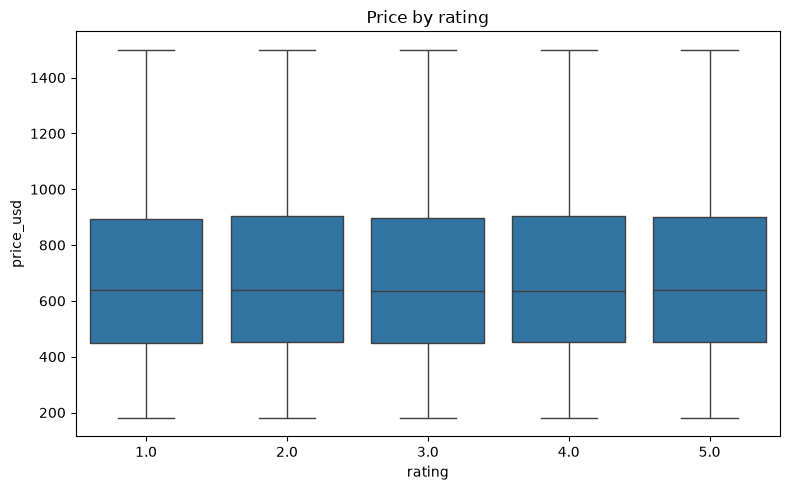

In [22]:
# price by rating
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='rating', y='price_usd')
plt.title('Price by rating')
plt.tight_layout(); plt.show()

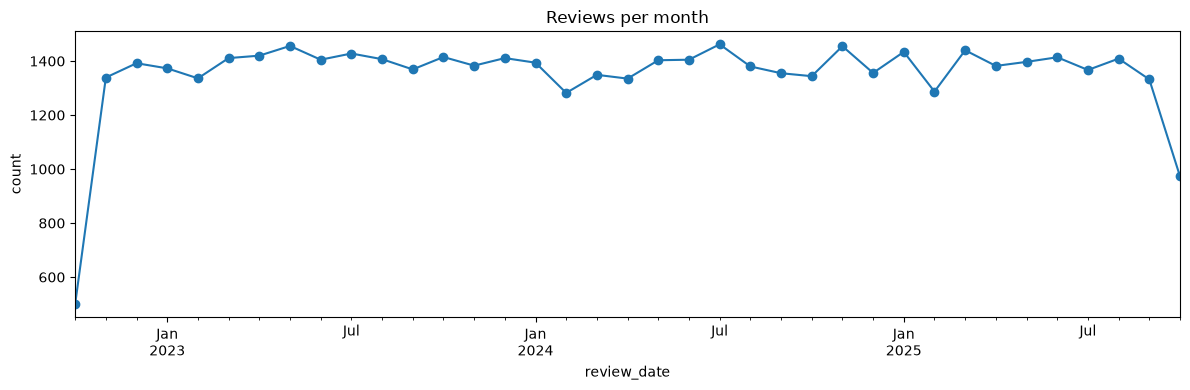

In [23]:
# reviews per month
monthly = df.set_index('review_date').resample('MS').agg(reviews=('rating', 'size'), avg_rating=('rating', 'mean'))

plt.figure(figsize=(12, 4))
monthly['reviews'].plot(marker='o')
plt.title('Reviews per month'); plt.ylabel('count')
plt.tight_layout(); plt.show()

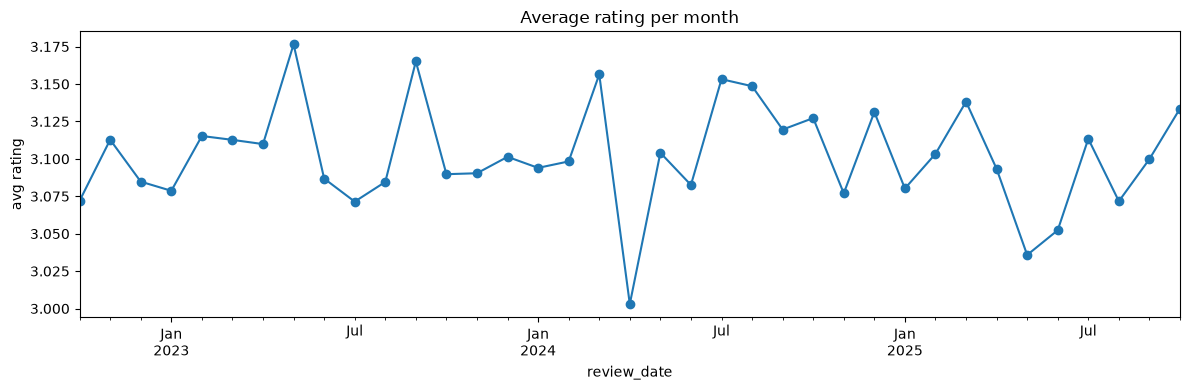

In [24]:
# average rating per month
plt.figure(figsize=(12, 4))
monthly['avg_rating'].plot(marker='o')
plt.title('Average rating per month'); plt.ylabel('avg rating')
plt.tight_layout(); plt.show()

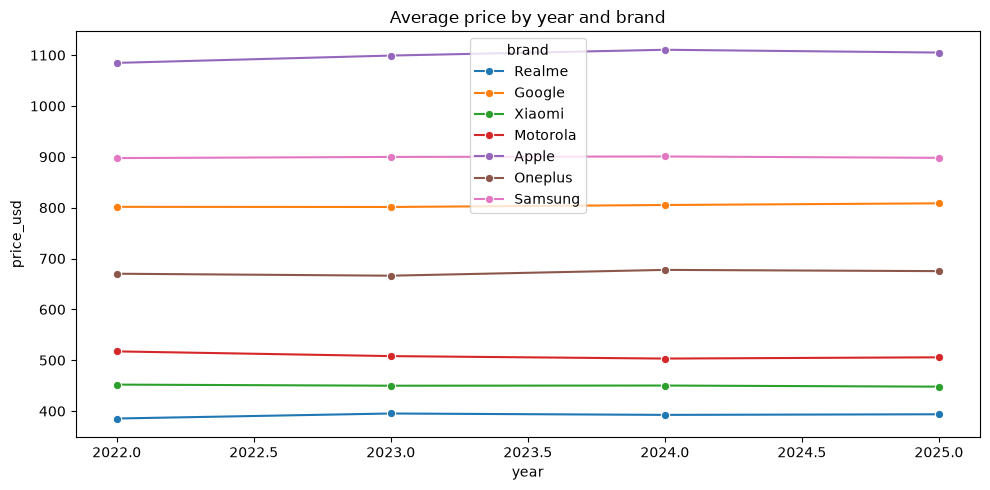

In [25]:
# average price per year by brand
df['year'] = df['review_date'].dt.year
plt.figure(figsize=(10, 5))
sns.lineplot(data=df, x='year', y='price_usd', hue='brand', marker='o', errorbar=None)
plt.title('Average price by year and brand')
plt.tight_layout(); plt.show()

In [26]:
product_df = (df.groupby(['brand', 'model'])
                .agg(reviews=('rating', 'size'),
                     avg_price=('price_usd', 'mean'),
                     avg_rating=('rating', 'mean'),
                     battery=('battery_life_rating', 'mean'),
                     camera=('camera_rating', 'mean'),
                     performance=('performance_rating', 'mean'),
                     design=('design_rating', 'mean'),
                     display=('display_rating', 'mean'),
                     helpful_votes=('helpful_votes', 'mean'),
                     positive_pct=('sentiment', lambda s: (s == 'Positive').mean() * 100))
                .round(2)
                .reset_index())

print(product_df.shape)
print(product_df)

(22, 12)
       brand            model  reviews  avg_price  avg_rating  battery  \
0      Apple        Iphone 13     1767    1108.27        3.13     2.75   
1      Apple        Iphone 14     1788    1099.22        3.15     2.74   
2      Apple    Iphone 15 Pro     1793    1103.41        3.06     2.68   
3      Apple        Iphone Se     1796    1103.38        3.08     2.73   
4     Google          Pixel 6     2379     807.92        3.09     2.71   
5     Google         Pixel 7A     2468     806.82        3.11     2.72   
6     Google          Pixel 8     2387     798.97        3.10     2.73   
7   Motorola          Edge 50     2315     508.70        3.07     2.67   
8   Motorola     Moto G Power     2351     504.61        3.12     2.72   
9   Motorola          Razr 40     2395     506.15        3.10     2.71   
10   Oneplus      Oneplus 11R     2433     672.79        3.10     2.70   
11   Oneplus       Oneplus 12     2323     670.61        3.11     2.73   
12   Oneplus   Oneplus Nord 3

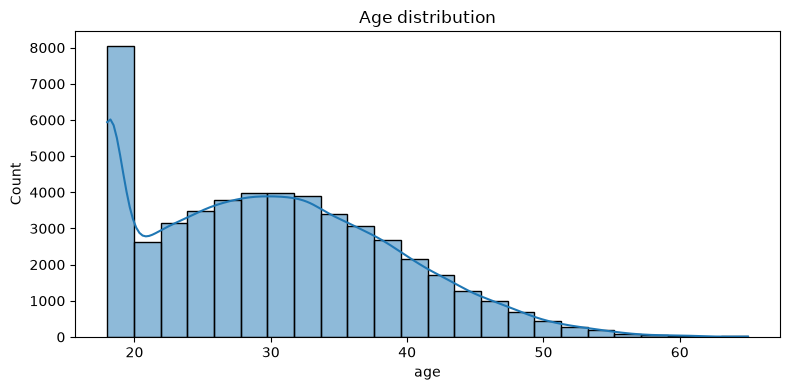

In [27]:
# age distribution
plt.figure(figsize=(8, 4))
sns.histplot(data = df, x = 'age', bins=24, kde=True)
plt.title('Age distribution')
plt.tight_layout(); plt.show()

In [28]:
# average price paid and rating by age group
df['age_group'] = pd.cut(df['age'], bins=[17, 24, 34, 44, 54, 65],
                         labels=['18-24', '25-34', '35-44', '45-54', '55-65'])

print(df.groupby('age_group', observed=True).agg(
    reviews=('rating', 'size'),
    avg_price=('price_usd', 'mean'),
    avg_rating=('rating', 'mean')).round(2))

           reviews  avg_price  avg_rating
age_group                                
18-24        15509     688.35        3.09
25-34        19168     690.37        3.11
35-44        11980     689.79        3.10
45-54         3072     693.07        3.15
55-65          271     676.36        3.17


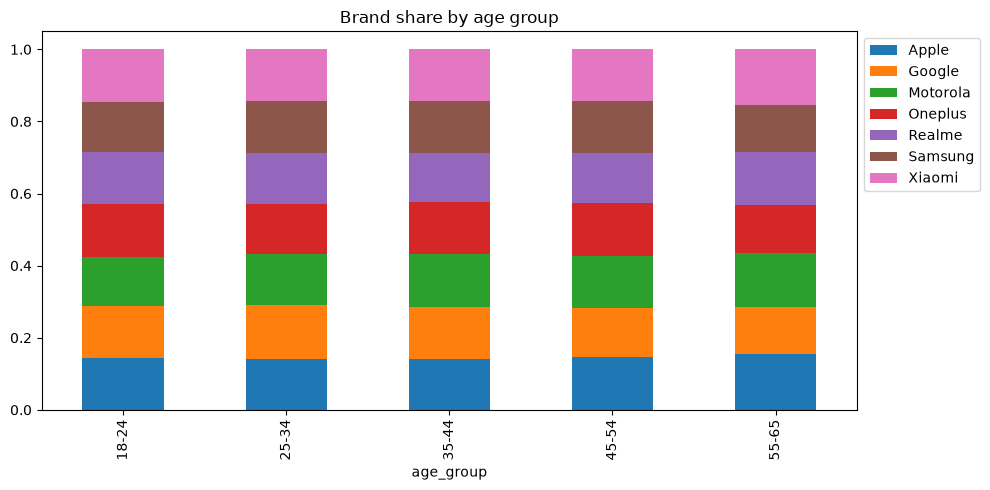

In [29]:
# brand preference by age group
pd.crosstab(df['age_group'], df['brand'], normalize='index').plot(kind='bar', stacked=True, figsize=(10, 5))
plt.title('Brand share by age group'); plt.legend(bbox_to_anchor=(1, 1))
plt.tight_layout(); plt.show()

The EDA on 50,000 reviews (7 brands, 22 models) shows a very uniform dataset. Brand, country and source are evenly spread, and sentiment is mostly Positive (56%). Price is the one clear separator. It is set by brand, from about $393 (Realme) to about $1,103 (Apple), with no outliers. Ratings are about 3.1 for every brand, model, country and age group, and price has no effect on rating. Review volume and ratings are flat over time. Reviewers skew young (about 70% are aged 18-34), but price, rating and brand preference are the same across ages. So price and the sub-ratings are the main features for segmentation into budget, mid-range and premium.